# Étape 5 : corrélation de Pearson ou information mutuelle ?

À l'étape 4, la régression linéaire mesurait le lien entre facteurs et rendements. Ici, on se demande si une mesure **non linéaire** du lien, l'information mutuelle, apporte quelque chose de plus.

Pour chaque facteur et chaque cible (Apple, puis le portefeuille diversifié de l'étape 4), on compare :
- la **corrélation de Pearson** et son test de significativité ;
- l'**information mutuelle** et son test de significativité.

Puis on cherche directement s'il reste un lien non linéaire une fois la régression linéaire estimée.

Le lien étudié reste **contemporain** (rendement du mois $t$ contre facteurs du mois $t$) : le but est explicatif, pas prédictif.

In [1]:
import io
import zipfile
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from statsmodels.nonparametric.smoothers_lowess import lowess

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 130)
rng = np.random.default_rng(2026)

## 1. Données

Mêmes données et même période que l'étape 4 : facteurs de Kenneth French, cours mensuels ajustés, de janvier 2000 à août 2026 (320 mois). Les cibles sont les rendements excédentaires ($R - R_f$, en %) d'Apple et du portefeuille équipondéré de 107 grandes capitalisations américaines.

In [2]:
def lire_bloc_mensuel(chemin_zip):
    # Lit le premier bloc de données (mensuel) d'un CSV de Kenneth French.
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float)


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
FACTEURS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]

cours = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)
cours.index = pd.PeriodIndex(cours.index.astype(str).str[:7], freq="M")
cours = cours.sort_index()
cours = cours[~cours.index.duplicated(keep="last")]
rendements = 100 * cours.pct_change(fill_method=None)

sys.path.insert(0, str(ROOT / "scripts"))
from univers import PORTEFEUILLE

DEBUT, FIN = pd.Period("2000-01", "M"), min(facteurs.index.max(), rendements.index.max())
periode = pd.period_range(DEBUT, FIN, freq="M")
candidats = [t for liste in PORTEFEUILLE.values() for t in liste]
disponibles = [t for t in candidats if t in rendements.columns
               and rendements.loc[periode, t].notna().all()]

F = facteurs.loc[periode]
R = rendements.loc[periode]
CIBLES = ["Apple (AAPL)", "Portefeuille diversifié"]
Y = pd.DataFrame({
    "Apple (AAPL)": R["AAPL"],
    "Portefeuille diversifié": R[disponibles].mean(axis=1),
}).sub(F["RF"], axis=0)
T = len(periode)
print(f"{DEBUT} -> {FIN} : {T} mois, portefeuille de {len(disponibles)} titres")

2000-01 -> 2026-08 : 320 mois, portefeuille de 107 titres


## 2. Les deux mesures du lien

### Corrélation de Pearson

$$\rho_{XY} = \frac{\mathrm{Cov}(X, Y)}{\sigma_X\,\sigma_Y} \in [-1, 1]$$

Elle mesure l'intensité d'un lien **linéaire**. Elle vaut 0 si $X$ et $Y$ sont indépendants, mais la réciproque est fausse : avec $X$ centré symétrique et $Y = X^2$, $Y$ dépend entièrement de $X$ et pourtant $\rho_{XY} = 0$.

**Test** : sous l'hypothèse $H_0 : \rho = 0$ (avec des données à peu près gaussiennes et indépendantes dans le temps),

$$t = \frac{\hat\rho\,\sqrt{T-2}}{\sqrt{1-\hat\rho^2}} \sim \text{Student}(T-2)$$

Avec $T = 320$, une corrélation est significative à 5 % dès que $|\hat\rho| > 0{,}11$.

### Information mutuelle

$$I(X;Y) = \iint p(x,y)\,\ln\frac{p(x,y)}{p(x)\,p(y)}\,dx\,dy \;\ge 0$$

Elle compare la loi jointe $p(x,y)$ au cas où $X$ et $Y$ seraient indépendants, $p(x)\,p(y)$. Elle vaut 0 **si et seulement si** $X$ et $Y$ sont indépendants : elle détecte tout type de lien, linéaire ou non. Elle s'exprime en *nats* (logarithme népérien) et n'a pas de signe.

**Pont avec Pearson** : si $(X, Y)$ est un couple gaussien de corrélation $\rho$,

$$I(X;Y) = -\tfrac{1}{2}\ln(1-\rho^2)$$

On en tire une **corrélation équivalente** $\rho_I = \sqrt{1 - e^{-2I}}$, comprise entre 0 et 1. Pour un couple gaussien, $\rho_I = |\rho|$. Si $\rho_I$ dépasse nettement $|\rho|$, l'information mutuelle voit un lien que la corrélation ne voit pas.

### Estimation de l'information mutuelle

La loi jointe est inconnue : on utilise l'estimateur des plus proches voisins de Kraskov, Stögbauer et Grassberger (2004), avec $k = 5$ voisins (implémentation `scikit-learn`).

Avant l'estimation, chaque variable est remplacée par ses **scores normaux** : on classe les observations, on transforme le rang $r$ en $\Phi^{-1}\big(r/(T+1)\big)$. L'information mutuelle ne change pas quand on transforme chaque variable de façon croissante, donc on ne perd rien. On gagne un estimateur plus stable, moins sensible aux mois extrêmes.

### Test de significativité de l'information mutuelle

Il n'existe pas de loi simple de l'estimateur sous $H_0$. On utilise un **test de permutation** : on mélange au hasard l'ordre des mois de $Y$, ce qui casse tout lien avec $X$, et on recalcule l'information mutuelle. Après 5 000 mélanges, on obtient la distribution de l'estimateur sous l'hypothèse d'indépendance. La p-valeur est la part des mélanges qui donnent une valeur au moins aussi grande que la valeur observée.

Grâce aux scores normaux, toutes les variables ont exactement les mêmes valeurs, dans un ordre différent. La distribution sous $H_0$ est donc **la même pour tous les couples** : on la calcule une seule fois.

In [3]:
K_VOISINS = 5
N_PERMUTATIONS = 5000


def scores_normaux(x):
    rangs = stats.rankdata(x)
    return stats.norm.ppf(rangs / (len(x) + 1))


def info_mutuelle(x, y, k=K_VOISINS):
    # Estimateur KSG sur les scores normaux, en nats.
    return mutual_info_regression(scores_normaux(x).reshape(-1, 1), scores_normaux(y),
                                  n_neighbors=k, random_state=0)[0]


def correlation_equivalente(i):
    return np.sqrt(1 - np.exp(-2 * np.maximum(i, 0)))


# Distribution de l'estimateur sous l'hypothèse d'indépendance (commune à tous les couples)
z = scores_normaux(np.arange(T))
nulle = np.array([info_mutuelle(z, rng.permutation(z)) for _ in range(N_PERMUTATIONS)])
seuil_im = np.quantile(nulle, 0.95)
seuil_pearson = stats.t.ppf(0.975, T - 2) / np.sqrt(T - 2 + stats.t.ppf(0.975, T - 2) ** 2)

print(f"Sous H0 : {np.mean(nulle == 0):.0%} des estimations valent exactement 0 (l'estimateur est tronqué à 0)")
print(f"Seuil à 5 % de l'information mutuelle : {seuil_im:.3f} nats, soit ρ_I = {correlation_equivalente(seuil_im):.2f}")
print(f"Seuil à 5 % de la corrélation de Pearson : |ρ| = {seuil_pearson:.2f}")

Sous H0 : 51% des estimations valent exactement 0 (l'estimateur est tronqué à 0)
Seuil à 5 % de l'information mutuelle : 0.050 nats, soit ρ_I = 0.31
Seuil à 5 % de la corrélation de Pearson : |ρ| = 0.11


## 3. Pearson contre information mutuelle, facteur par facteur

In [4]:
def p_valeur_permutation(i):
    return (1 + np.sum(nulle >= i)) / (len(nulle) + 1)


lignes = []
for cible in CIBLES:
    for f in FACTEURS:
        x, y = F[f].values, Y[cible].values
        rho, p_rho = stats.pearsonr(x, y)
        im = info_mutuelle(x, y)
        lignes.append({
            "cible": cible, "facteur": f,
            "ρ Pearson": rho, "p-valeur ρ": p_rho,
            "IM (nats)": im, "ρ_I": correlation_equivalente(im), "p-valeur IM": p_valeur_permutation(im),
        })
comparaison = pd.DataFrame(lignes).set_index(["cible", "facteur"])
comparaison["Pearson significatif"] = comparaison["p-valeur ρ"] < 0.05
comparaison["IM significative"] = comparaison["p-valeur IM"] < 0.05
comparaison.round(3)

ρ Pearson  p-valeur ρ  IM (nats)    ρ_I  p-valeur IM  Pearson significatif  IM significative
cible                   facteur                                                                                              
Apple (AAPL)            Mkt-RF       0.548       0.000      0.246  0.623        0.000                  True              True
                        SMB          0.146       0.009      0.023  0.214        0.203                  True             False
                        HML         -0.257       0.000      0.067  0.353        0.015                  True              True
                        RMW         -0.234       0.000      0.000  0.000        1.000                  True             False
                        CMA         -0.352       0.000      0.052  0.316        0.042                  True              True
                        Mom         -0.164       0.003      0.000  0.000        1.000                  True             False
Portefeuille diversifié Mkt-RF       0.914       0.000      1.121  0.945        0.000                  True              True
                        SMB          0.215       0.000      0.002  0.061        0.465                  True             False
                        HML          0.243       0.000      0.033  0.251        0.134                  True             False
                        RMW         -0.139       0.013      0.067  0.355        0.014                  True              True
                        CMA          0.021       0.710      0.015  0.172        0.303                 False             False
                        Mom         -0.425       0.000      0.098  0.421        0.002                  True              True

In [5]:
pd.crosstab(comparaison["Pearson significatif"], comparaison["IM significative"],
            rownames=["Pearson significatif"], colnames=["IM significative"])

IM significative,False,True
Pearson significatif,,
False,1,0
True,5,6


### Robustesse au nombre de voisins

L'estimateur dépend du nombre de voisins $k$. On vérifie que les conclusions ne tiennent pas à ce choix.

In [6]:
sensibilite = pd.DataFrame({
    f"k = {k}": [info_mutuelle(F[f].values, Y[c].values, k=k) for c in CIBLES for f in FACTEURS]
    for k in [3, 5, 10, 20]
}, index=comparaison.index)
sensibilite.round(3)

k = 3  k = 5  k = 10  k = 20
cible                   facteur                              
Apple (AAPL)            Mkt-RF   0.243  0.246   0.234   0.221
                        SMB      0.000  0.023   0.017   0.000
                        HML      0.076  0.067   0.010   0.021
                        RMW      0.000  0.000   0.000   0.013
                        CMA      0.058  0.052   0.053   0.054
                        Mom      0.032  0.000   0.025   0.029
Portefeuille diversifié Mkt-RF   1.110  1.121   1.105   1.040
                        SMB      0.000  0.002   0.023   0.040
                        HML      0.029  0.033   0.010   0.016
                        RMW      0.052  0.067   0.063   0.051
                        CMA      0.055  0.015   0.029   0.015
                        Mom      0.041  0.098   0.089   0.086

## 4. Pourquoi les deux tests ne concluent pas pareil : la puissance

La **puissance** d'un test est la probabilité de détecter un lien qui existe vraiment. On la mesure par simulation, avec $T = 320$ observations comme dans nos données, dans deux situations :

1. **Lien linéaire** : $(X, Y)$ gaussien de corrélation $\rho$. C'est le terrain de Pearson.
2. **Lien en U** : $Y = a\,(X^2 - 1) + \varepsilon$, avec $X$ et $\varepsilon$ gaussiens indépendants. Ici $\rho = 0$ quelle que soit l'intensité $a$ : c'est le terrain de l'information mutuelle.

Pour chaque intensité, on simule 400 échantillons et on compte la part où chaque test rejette l'indépendance au seuil de 5 %.

In [7]:
N_SIMULATIONS = 400


def puissance(generateur, intensites):
    res = []
    for a in intensites:
        rejets_p, rejets_im = 0, 0
        for _ in range(N_SIMULATIONS):
            x, y = generateur(a)
            rejets_p += stats.pearsonr(x, y)[1] < 0.05
            rejets_im += info_mutuelle(x, y) > seuil_im
        res.append({"intensité": a, "Pearson": rejets_p / N_SIMULATIONS,
                    "Information mutuelle": rejets_im / N_SIMULATIONS})
    return pd.DataFrame(res).set_index("intensité")


def lineaire(rho):
    x = rng.standard_normal(T)
    return x, rho * x + np.sqrt(1 - rho ** 2) * rng.standard_normal(T)


def en_u(a):
    x = rng.standard_normal(T)
    return x, a * (x ** 2 - 1) + rng.standard_normal(T)


puissance_lineaire = puissance(lineaire, np.round(np.arange(0, 0.41, 0.025), 3))
puissance_u = puissance(en_u, np.round(np.arange(0, 0.41, 0.025), 3))
pd.concat({"lien linéaire (ρ)": puissance_lineaire, "lien en U (a)": puissance_u}, axis=1).round(2)

lien linéaire (ρ)                      lien en U (a)                     
                    Pearson Information mutuelle       Pearson Information mutuelle
intensité                                                                          
0.000                  0.04                 0.03          0.06                 0.04
0.025                  0.08                 0.05          0.07                 0.05
0.050                  0.14                 0.04          0.08                 0.07
0.075                  0.24                 0.07          0.06                 0.06
0.100                  0.52                 0.09          0.05                 0.06
0.125                  0.65                 0.08          0.08                 0.11
0.150                  0.77                 0.09          0.08                 0.16
0.175                  0.87                 0.13          0.08                 0.22
0.200                  0.94                 0.14          0.11                 0.34
0.225                  0.98                 0.21          0.11                 0.41
0.250                  0.99                 0.28          0.11                 0.52
0.275                  1.00                 0.40          0.08                 0.60
0.300                  1.00                 0.47          0.12                 0.70
0.325                  1.00                 0.54          0.14                 0.80
0.350                  1.00                 0.67          0.18                 0.90
0.375                  1.00                 0.77          0.17                 0.93
0.400                  1.00                 0.88          0.14                 0.96

## 5. L'information mutuelle voit-elle plus que la corrélation ?

Si le lien entre un facteur et une cible était purement linéaire et gaussien, l'information mutuelle vaudrait $-\tfrac12\ln(1-\rho^2)$. On teste l'écart à ce cas de référence.

- $\rho_{SN}$ : corrélation de Pearson entre les **scores normaux** des deux variables.
- Sous $H_0$ « lien gaussien », on simule 1 000 échantillons gaussiens de 320 mois avec la corrélation $\rho_{SN}$, et on leur applique exactement le même estimateur.
- La p-valeur est la part des simulations dont l'information mutuelle dépasse celle observée.

Une p-valeur faible signale une information **en plus** de la corrélation : lien non linéaire, ou dépendance plus forte dans les extrêmes (par exemple, des chutes simultanées en crise).

In [8]:
N_GAUSS = 1000


def test_exces_gaussien(x, y):
    zx, zy = scores_normaux(x), scores_normaux(y)
    rho_sn = np.corrcoef(zx, zy)[0, 1]
    im_obs = info_mutuelle(x, y)
    sim = []
    for _ in range(N_GAUSS):
        u = rng.standard_normal(T)
        v = rho_sn * u + np.sqrt(1 - rho_sn ** 2) * rng.standard_normal(T)
        sim.append(info_mutuelle(u, v))
    sim = np.array(sim)
    return {"ρ_SN": rho_sn, "IM observée": im_obs, "IM si lien gaussien (médiane)": np.median(sim),
            "p-valeur excès": (1 + np.sum(sim >= im_obs)) / (N_GAUSS + 1)}


exces = pd.DataFrame({(c, f): test_exces_gaussien(F[f].values, Y[c].values)
                      for c in CIBLES for f in FACTEURS}).T
exces.index.names = ["cible", "facteur"]
exces.round(3)

ρ_SN  IM observée  IM si lien gaussien (médiane)  p-valeur excès
cible                   facteur                                                                   
Apple (AAPL)            Mkt-RF   0.577        0.246                          0.208           0.190
                        SMB      0.156        0.023                          0.011           0.342
                        HML     -0.231        0.067                          0.028           0.107
                        RMW     -0.205        0.000                          0.024           1.000
                        CMA     -0.328        0.052                          0.058           0.559
                        Mom     -0.131        0.000                          0.005           1.000
Portefeuille diversifié Mkt-RF   0.913        1.121                          0.907           0.001
                        SMB      0.263        0.002                          0.034           0.855
                        HML      0.211        0.033                          0.020           0.357
                        RMW     -0.209        0.067                          0.023           0.083
                        CMA      0.036        0.015                          0.000           0.291
                        Mom     -0.401        0.098                          0.088           0.400

## 6. Reste-t-il un lien non linéaire après la régression ?

La question la plus directe : une fois la régression linéaire de l'étape 4 estimée, ses **résidus** $\hat\varepsilon_t$ dépendent-ils encore des facteurs ?

Par construction des MCO, les résidus ne sont pas corrélés aux facteurs : $\mathrm{Corr}(\hat\varepsilon, F_k) = 0$ exactement. Toute information mutuelle significative entre $\hat\varepsilon$ et $F_k$ est donc **non linéaire**.

Deux tests :
1. **Information mutuelle** entre les résidus et chaque facteur, avec le test de permutation de la partie 2.
2. **Régression quadratique** : on ajoute les carrés des six facteurs à la régression,

$$y_t = \alpha + \sum_k b_k F_{k,t} + \sum_k q_k F_{k,t}^2 + \varepsilon_t$$

puis on teste $q_1 = \dots = q_6 = 0$ (test de Wald avec erreurs standard de Newey-West, 6 retards). On regarde aussi le gain de $R^2$ ajusté : c'est l'intérêt pratique du non-linéaire.

In [9]:
def regression(y, X, retards=6):
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": retards})


residus_im, quadratique = [], {}
for c in CIBLES:
    lin = regression(Y[c], F[FACTEURS])
    for f in FACTEURS:
        im = info_mutuelle(F[f].values, lin.resid.values)
        residus_im.append({"cible": c, "facteur": f, "corrélation": np.corrcoef(F[f], lin.resid)[0, 1],
                           "IM résidus (nats)": im, "p-valeur": p_valeur_permutation(im)})
    carres = F[FACTEURS] ** 2
    carres.columns = [f"{f}²" for f in FACTEURS]
    quad = regression(Y[c], pd.concat([F[FACTEURS], carres], axis=1))
    wald = quad.wald_test(np.eye(13)[7:], scalar=True)
    quadratique[c] = {"R² linéaire": lin.rsquared, "R² quadratique": quad.rsquared,
                      "R² ajusté linéaire": lin.rsquared_adj, "R² ajusté quadratique": quad.rsquared_adj,
                      "p-valeur Wald (6 carrés)": wald.pvalue,
                      "plus petite p-valeur d'un carré": quad.pvalues[carres.columns].min()}

residus_im = pd.DataFrame(residus_im).set_index(["cible", "facteur"])
residus_im.round(3)

corrélation  IM résidus (nats)  p-valeur
cible                   facteur                                          
Apple (AAPL)            Mkt-RF           0.0              0.014     0.314
                        SMB              0.0              0.000     1.000
                        HML             -0.0              0.005     0.420
                        RMW             -0.0              0.000     1.000
                        CMA             -0.0              0.001     0.473
                        Mom             -0.0              0.000     1.000
Portefeuille diversifié Mkt-RF          -0.0              0.004     0.437
                        SMB             -0.0              0.000     1.000
                        HML             -0.0              0.074     0.008
                        RMW             -0.0              0.000     1.000
                        CMA             -0.0              0.022     0.219
                        Mom             -0.0              0.072     0.009

In [10]:
pd.DataFrame(quadratique).round(4)

,Apple (AAPL),Portefeuille diversifié
R² linéaire,0.370,0.939
R² quadratique,0.385,0.940
R² ajusté linéaire,0.358,0.938
R² ajusté quadratique,0.360,0.938
p-valeur Wald (6 carrés),0.079,0.181
plus petite p-valeur d'un carré,0.144,0.219


**Tests multiples** : on fait ici 12 tests (6 facteurs × 2 cibles). Même sans aucun lien réel, on s'attend à environ $12 \times 5\,\% \approx 0{,}6$ rejet à tort au seuil de 5 %. La correction de Bonferroni demande une p-valeur inférieure à $0{,}05/12 \approx 0{,}004$ pour conclure.

In [11]:
print("Résidus : p-valeurs sous 5 % :", (residus_im["p-valeur"] < 0.05).sum(),
      "| sous le seuil de Bonferroni (0,05/12) :", (residus_im["p-valeur"] < 0.05 / 12).sum())

Résidus : p-valeurs sous 5 % : 2 | sous le seuil de Bonferroni (0,05/12) : 0


### D'où vient le signal résiduel ?

L'information mutuelle détecte toute dépendance, y compris une dépendance de la **variance** : les résidus peuvent être plus dispersés quand un facteur bouge fortement, sans que leur moyenne change. Cette forme de lien n'améliore pas l'explication du rendement. On le vérifie en corrélant $|\hat\varepsilon_t|$ et $|F_{k,t}|$.

In [12]:
dispersion = {}
for c in CIBLES:
    e = regression(Y[c], F[FACTEURS]).resid
    dispersion[c] = {f: stats.spearmanr(np.abs(F[f]), np.abs(e))[0] for f in FACTEURS}
dispersion = pd.DataFrame(dispersion)
dispersion.index.name = "corrélation de rang entre |facteur| et |résidu|"
dispersion.round(3)

,Apple (AAPL),Portefeuille diversifié
corrélation de rang entre |facteur| et |résidu|,,
Mkt-RF,0.057,0.018
SMB,-0.010,0.105
HML,0.044,0.238
RMW,0.066,0.098
CMA,0.166,0.138
Mom,0.127,0.052


## 7. Graphiques

In [13]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
BLEU_CLAIR, ORANGE_CLAIR = "#bcd5f2", "#f7c9b5"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")

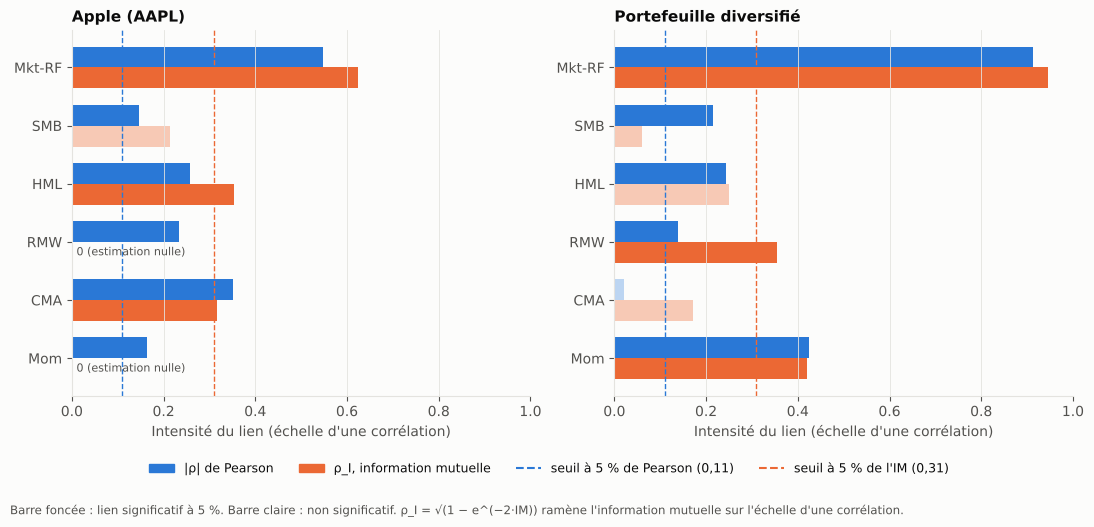

In [14]:
# Intensité du lien et seuils de significativité, sur une même échelle de corrélation
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True)
y_pos = np.arange(len(FACTEURS))
h = 0.36
for ax, c in zip(axes, CIBLES):
    d = comparaison.loc[c]
    for i, f in enumerate(FACTEURS):
        sig_p, sig_i = d.loc[f, "Pearson significatif"], d.loc[f, "IM significative"]
        ax.barh(i - h / 2, abs(d.loc[f, "ρ Pearson"]), height=h, color=BLEU if sig_p else BLEU_CLAIR,
                label=None)
        ax.barh(i + h / 2, d.loc[f, "ρ_I"], height=h, color=ORANGE if sig_i else ORANGE_CLAIR)
        if d.loc[f, "ρ_I"] < 0.01:
            ax.text(0.01, i + h / 2, "0 (estimation nulle)", va="center", fontsize=8, color=TEXTE2)
    ax.axvline(seuil_pearson, color=BLEU, lw=1, ls="--")
    ax.axvline(correlation_equivalente(seuil_im), color=ORANGE, lw=1, ls="--")
    ax.set_yticks(y_pos, FACTEURS)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(c)
    ax.set_xlabel("Intensité du lien (échelle d'une corrélation)")
axes[0].set_xlim(0, 1)
poignees = [plt.Rectangle((0, 0), 1, 1, color=BLEU), plt.Rectangle((0, 0), 1, 1, color=ORANGE),
            plt.Line2D([], [], color=BLEU, ls="--"), plt.Line2D([], [], color=ORANGE, ls="--")]
fig.legend(poignees, ["|ρ| de Pearson", "ρ_I, information mutuelle",
                      f"seuil à 5 % de Pearson ({seuil_pearson:.2f})".replace(".", ","),
                      f"seuil à 5 % de l'IM ({correlation_equivalente(seuil_im):.2f})".replace(".", ",")],
           ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.07), fontsize=9)
fig.text(0.01, -0.13, "Barre foncée : lien significatif à 5 %. Barre claire : non significatif. "
         "ρ_I = √(1 − e^(−2·IM)) ramène l'information mutuelle sur l'échelle d'une corrélation.",
         fontsize=8.5, color=TEXTE2)
fig.tight_layout()
sauver(fig, "mi_pearson_significativite.png")
plt.show()

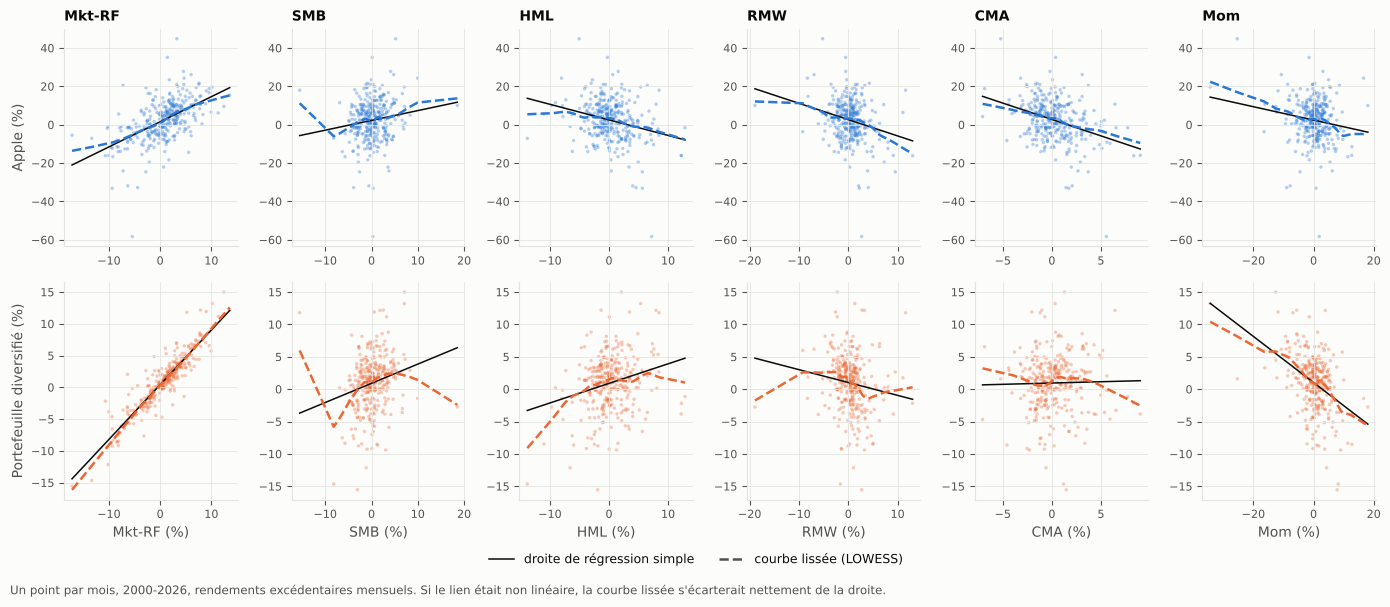

In [15]:
# Nuages de points : droite de régression simple et courbe lissée (LOWESS)
fig, axes = plt.subplots(2, 6, figsize=(14, 5.6))
for ligne, (c, col) in enumerate(zip(CIBLES, [BLEU, ORANGE])):
    for j, f in enumerate(FACTEURS):
        ax = axes[ligne, j]
        x, y = F[f].values, Y[c].values
        ax.scatter(x, y, s=6, color=col, alpha=0.35, edgecolor="none")
        pente, origine = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(xs, origine + pente * xs, color=TEXTE, lw=1.1)
        lisse = lowess(y, x, frac=0.5, return_sorted=True)
        ax.plot(lisse[:, 0], lisse[:, 1], color=col, lw=1.8, ls="--")
        ax.tick_params(labelsize=8)
        if ligne == 1:
            ax.set_xlabel(f"{f} (%)")
        if ligne == 0:
            ax.set_title(f, fontsize=10)
    axes[ligne, 0].set_ylabel(f"{c.split(' (')[0]} (%)")
poignees = [plt.Line2D([], [], color=TEXTE, lw=1.1), plt.Line2D([], [], color=TEXTE2, lw=1.8, ls="--")]
fig.legend(poignees, ["droite de régression simple", "courbe lissée (LOWESS)"], ncol=2,
           loc="lower center", bbox_to_anchor=(0.5, -0.04), fontsize=9)
fig.text(0.01, -0.07, "Un point par mois, 2000-2026, rendements excédentaires mensuels. "
         "Si le lien était non linéaire, la courbe lissée s'écarterait nettement de la droite.",
         fontsize=8.5, color=TEXTE2)
fig.tight_layout()
sauver(fig, "mi_nuages_points.png")
plt.show()

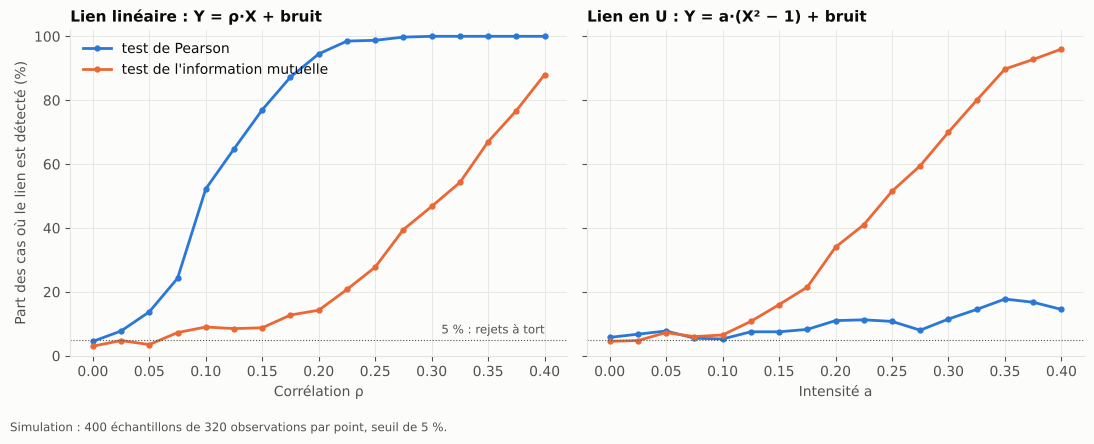

In [16]:
# Puissance des deux tests
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, tab, titre, xlabel in [
        (axes[0], puissance_lineaire, "Lien linéaire : Y = ρ·X + bruit", "Corrélation ρ"),
        (axes[1], puissance_u, "Lien en U : Y = a·(X² − 1) + bruit", "Intensité a")]:
    ax.plot(tab.index, 100 * tab["Pearson"], color=BLEU, lw=2, marker="o", ms=3.5, label="test de Pearson")
    ax.plot(tab.index, 100 * tab["Information mutuelle"], color=ORANGE, lw=2, marker="o", ms=3.5,
            label="test de l'information mutuelle")
    ax.axhline(5, color=TEXTE2, lw=0.8, ls=":")
    ax.set_title(titre)
    ax.set_xlabel(xlabel)
    ax.set_ylim(0, 102)
axes[0].text(0.4, 7, "5 % : rejets à tort", color=TEXTE2, fontsize=8.5, ha="right")
axes[0].set_ylabel("Part des cas où le lien est détecté (%)")
axes[0].legend(loc="upper left")
fig.text(0.01, -0.04, f"Simulation : {N_SIMULATIONS} échantillons de {T} observations par point, seuil de 5 %.",
         fontsize=8.5, color=TEXTE2)
fig.tight_layout()
sauver(fig, "mi_puissance_tests.png")
plt.show()